# Function Encoders as Learned Kernels

**Learning Objectives**
- Build the kernel $\kappa(x, x') = \boldsymbol{\phi}(x)^T \boldsymbol{\phi}(x')$ of a trained function encoder and check that it is symmetric positive semidefinite
- Show that the primal least-squares solution and the dual kernel ridge solution give the same predictor, and compare their costs
- Read the number of basis functions a family needs from the eigenvalues of the coefficient covariance
- Implement train-then-prune and progressive training of a function encoder basis

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/03-function-encoder/03-fe-kernels.ipynb)
[![View Slides](https://img.shields.io/badge/View-Presentation-yellow?style=flat-square&logo=googleslides&logoColor=white)](https://raw.githubusercontent.com/kks32-courses/sciml/main/docs/03-function-encoder/b2b.pdf)

A function encoder represents every function of a family as $\hat f(x) = \sum_{j=1}^k \alpha_j \phi_j(x)$.
The basis functions $\phi_j$ are neural networks trained on the family, and the coefficients $\alpha_j$ come from least squares.
Low, Rommel, Miller, Thorpe, and Topcu, "Function Spaces Without Kernels" (arXiv:2509.20605), show that the trained basis defines a kernel.
A function encoder is then a kernel method whose kernel is learned from the family.
We follow their argument on a bridge deck under traffic.
We train a basis, build its kernel, solve one regression in the primal and in the dual, and use the coefficient covariance to decide how many basis functions the family needs.
Low et al. write $\psi_j$ for the basis functions, $c$ for the coefficients, and $n$ for their number.
We keep the notation of `03-function-encoder.ipynb`, with $\phi_j$, $\alpha$, and $k$.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
device = torch.device("cpu")
rng = np.random.default_rng(0)

## The example and the data

A simply supported bridge deck of length $L = 1$ and bending stiffness $EI = 1$ carries a traffic load $q(x)$.
The deflection $w(x)$, positive downward, solves the beam equation

$$EI \frac{d^4 w}{dx^4} = q(x), \qquad w(0) = w(L) = 0, \qquad \frac{d^2 w}{dx^2}(0) = \frac{d^2 w}{dx^2}(L) = 0.$$

The supports fix the deflection and carry no bending moment, which gives the four boundary conditions.
Each sine $\sin(j\pi x)$ satisfies all four, and $\frac{d^4}{dx^4}\sin(j\pi x) = (j\pi)^4 \sin(j\pi x)$.
A load mode $q_j \sin(j\pi x)$ therefore produces the deflection mode $q_j \sin(j\pi x) / (EI\,(j\pi)^4)$.
The beam divides load mode $j$ by $(j\pi)^4$, so short wavelengths in the load leave little trace in the deflection.

Family A is a distributed load built from five sine modes,

$$q(x) = \sum_{j=1}^{5} a_j\, j^4 \sin(j\pi x), \qquad w(x) = \frac{1}{\pi^4} \sum_{j=1}^{5} a_j \sin(j\pi x),$$

with each $a_j$ drawn uniformly from $[-1, 1]$.
Every deflection lies in the span of $\sin(\pi x), \dots, \sin(5\pi x)$, so the deflections of family A fill a 5-dimensional space.
The factor $j^4$ in the load gives every deflection mode the same range $[-1/\pi^4, 1/\pi^4]$.

Family B models vehicles.
A vehicle has one to three axles, a spacing between neighboring axles drawn from $[0.1, 0.25]$, a random position on the deck, and axle loads $P$ drawn uniformly from $[0.5, 2]$.
A point load $P$ at position $a$, with $b = L - a$, deflects the deck by

$$w(x) = \frac{P\, b\, x\,(L^2 - b^2 - x^2)}{6\, EI\, L} \quad \text{for } x \le a, \qquad w(x) = \frac{P\, a\,(L - x)\,(L^2 - a^2 - (L - x)^2)}{6\, EI\, L} \quad \text{for } x > a,$$

and the deflection under a vehicle is the sum over its axles.
The point load has the sine coefficients $2P\sin(j\pi a)$, so the same deflection is the series $w(x) = \sum_{j \ge 1} 2P \sin(j\pi a) \sin(j\pi x) / (EI\,(j\pi)^4)$.
Every mode appears, and the deflections of family B span an infinite-dimensional space.
The factor $(j\pi)^{-4}$ makes the mode amplitudes decay fast.
Low et al. observe a gradual spectrum of this kind in their two-body example (Section 6.2.2), while family A plays the role of their polynomial benchmark with a known dimension (Section 6.1, Figure 1).

We sample each deflection on $m = 200$ grid points and draw $N = 600$ training and 200 test functions per family.
The code checks the closed form against 4000 terms of the sine series.

In [2]:
L, EI = 1.0, 1.0
m = 200
N_train, N_test = 600, 200
x = np.linspace(0.0, L, m)
modes = np.arange(1, 6)


def family_A(n, x):
    """Load q = sum_j a_j j^4 sin(j pi x) with a_j ~ U[-1, 1]. Returns (q, w)."""
    a = rng.uniform(-1.0, 1.0, size=(n, len(modes)))
    S = np.sin(np.pi * np.outer(modes, x))
    q = (a * modes**4) @ S
    w = (a / np.pi**4) @ S          # w_j = q_j / (EI (j pi)^4)
    return q, w


def point_load_deflection(x, P, a):
    """Simply supported beam, point load P at position a."""
    b = L - a
    left = P * b * x * (L**2 - b**2 - x**2) / (6 * EI * L)
    xr = L - x
    right = P * a * xr * (L**2 - a**2 - xr**2) / (6 * EI * L)
    return np.where(x <= a, left, right)


def sample_vehicle():
    n_axles = rng.integers(1, 4)
    spacing = rng.uniform(0.1, 0.25, size=n_axles - 1)
    front = rng.uniform(0.0, L - spacing.sum())
    positions = front + np.concatenate([[0.0], np.cumsum(spacing)])
    loads = rng.uniform(0.5, 2.0, size=n_axles)
    return positions, loads


def vehicle_deflection(x, positions, loads):
    return sum(point_load_deflection(x, P, a) for a, P in zip(positions, loads))


def family_B(n, x):
    vehicles = [sample_vehicle() for _ in range(n)]
    w = np.array([vehicle_deflection(x, *v) for v in vehicles])
    return vehicles, w


qA_train, wA_train = family_A(N_train, x)
qA_test, wA_test = family_A(N_test, x)
veh_train, wB_train = family_B(N_train, x)
veh_test, wB_test = family_B(N_test, x)

# Check the closed form against the sine series w = sum_j 2 P sin(j pi a) sin(j pi x) / (EI (j pi)^4)
j = np.arange(1, 4001)
P0, a0 = 1.0, 0.3
series = (2 * P0 * np.sin(j * np.pi * a0) / (EI * (j * np.pi)**4)) @ np.sin(np.pi * np.outer(j, x))
print(f"max |closed form - sine series| = {np.abs(point_load_deflection(x, P0, a0) - series).max():.2e}")

# Share of deflection variance per mode if the load amplitudes were a_j ~ U[-1, 1] without the j^4 factor
evr_flat = modes**-8.0 / np.sum(modes**-8.0)
print("explained variance ratio per mode, flat load amplitudes:", np.array2string(evr_flat, precision=3))

scale_A = np.sqrt(np.mean(wA_train**2))
scale_B = np.sqrt(np.mean(wB_train**2))
print(f"RMS deflection: family A {scale_A:.3e}, family B {scale_B:.3e}")

max |closed form - sine series| = 9.33e-16
explained variance ratio per mode, flat load amplitudes: [9.959e-01 3.890e-03 1.518e-04 1.520e-05 2.550e-06]
RMS deflection: family A 9.365e-03, family B 3.020e-02


The closed form and the series agree to $9.33 \times 10^{-16}$.

The second printed line explains the factor $j^4$ in family A.
With load amplitudes $a_j \sin(j\pi x)$ and no factor, deflection mode $j$ has size $(j\pi)^{-4}$, its variance scales as $j^{-8}$, and mode $j$ carries the share $j^{-8} / \sum_{i=1}^5 i^{-8}$ of the deflection variance.
The first mode would carry 0.9959 of the variance and a 99 percent threshold would keep one mode out of five.
With the factor $j^4$ the five modes carry equal variance, and the dimension 5 shows up in the variance.

The two families also differ in size.
We divide each family by the root mean square of its training deflections, printed in the last line, so that every reported MSE is relative to the mean square of the deflections.
The figure shows four samples of each family, with the loads on top and the deflections below.

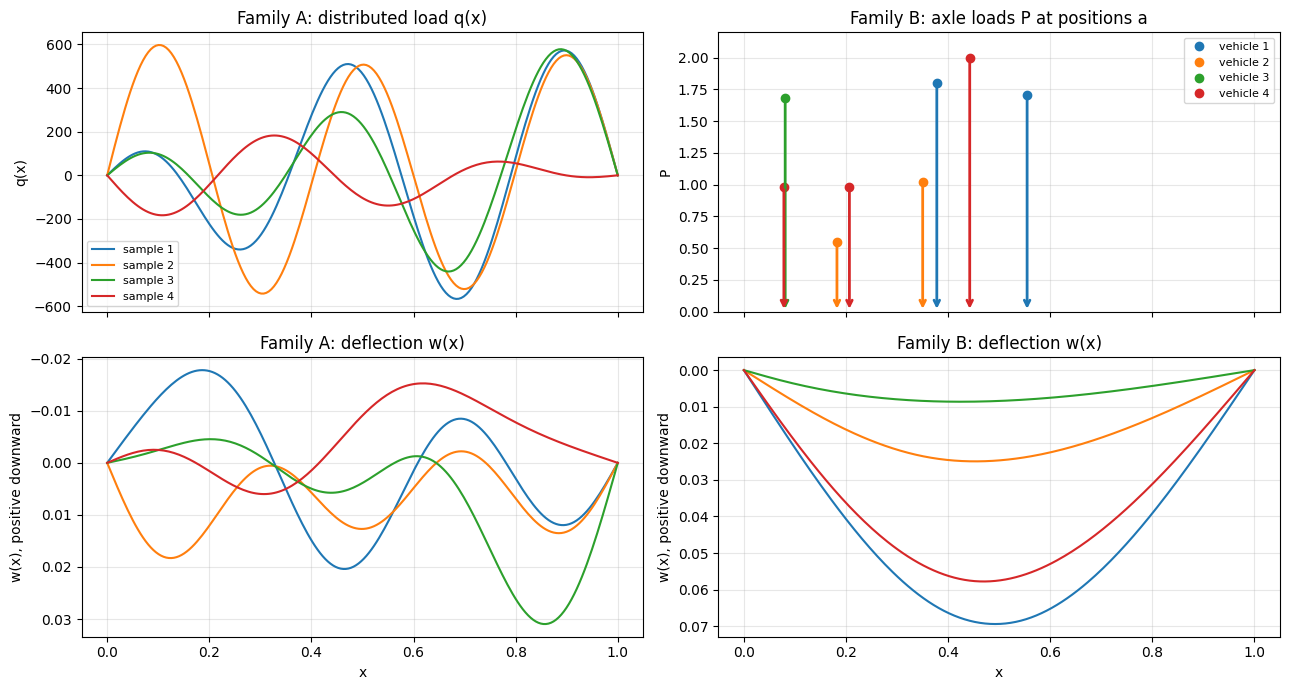

In [3]:
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)

for i, c in enumerate(colors):
    axes[0, 0].plot(x, qA_train[i], color=c, label=f"sample {i + 1}")
    axes[1, 0].plot(x, wA_train[i], color=c)
    positions, loads = veh_train[i]
    for a, P in zip(positions, loads):
        axes[0, 1].annotate("", xy=(a, 0.0), xytext=(a, P),
                            arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[0, 1].plot(positions, loads, "o", color=c, label=f"vehicle {i + 1}")
    axes[1, 1].plot(x, wB_train[i], color=c)

axes[0, 0].set_title("Family A: distributed load q(x)")
axes[0, 0].set_ylabel("q(x)")
axes[0, 0].legend(fontsize=8)
axes[0, 1].set_title("Family B: axle loads P at positions a")
axes[0, 1].set_ylabel("P")
axes[0, 1].set_ylim(0, 2.2)
axes[0, 1].legend(fontsize=8)
axes[1, 0].set_title("Family A: deflection w(x)")
axes[1, 1].set_title("Family B: deflection w(x)")
for ax in axes[1]:
    ax.set_xlabel("x")
    ax.set_ylabel("w(x), positive downward")
    ax.invert_yaxis()
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## A function encoder on the bridge data

A function encoder learns $k$ basis functions $\phi_1, \dots, \phi_k$ and represents a deflection by $\hat f(x) = \sum_{j=1}^k \alpha_j \phi_j(x)$.
Each basis function is a separate MLP with two hidden layers of width 32 and tanh activations, as in Part 3 of `03-function-encoder.ipynb`.
On the grid the basis becomes the matrix $\Phi \in \mathbb{R}^{m \times k}$ with $\Phi_{ij} = \phi_j(x_i)$.
For a deflection sampled as $f \in \mathbb{R}^m$, the coefficients solve the ridge normal equations

$$(\Phi^T \Phi + \lambda I)\, \alpha = \Phi^T f,$$

with $\lambda = 10^{-3}$.
Low et al. write the same system with averages over the samples, $(\frac{1}{m}\Phi^T\Phi + \lambda' I)\,\alpha = \frac{1}{m}\Phi^T f$ (their equation (3)), so $\lambda = m \lambda'$.

Training adjusts the networks so that these least-squares fits are accurate for all training functions at once.
The loss is

$$\mathcal{L} = \frac{1}{Nm} \sum_{n=1}^{N} \| f_n - \Phi \alpha_n \|^2 + \mu \, \| G - I \|_F^2, \qquad G = \frac{1}{m} \Phi^T \Phi,$$

where $\alpha_n$ solves the normal equations for the training function $f_n$ and $\mu = 10^{-2}$.
The Gram matrix $G$ holds the inner products $\langle \phi_i, \phi_j \rangle \approx \int_0^1 \phi_i \phi_j \, dx$.
The diagonal terms $\sum_i (\|\phi_i\|^2 - 1)^2$ of the penalty form the norm regularizer of Ingebrand, Thorpe, and Topcu (arXiv:2501.18373, Appendix A).
The ridge term shrinks every fit a little, and without the norm regularizer the basis functions grow to offset the shrinkage.
The off-diagonal terms push the basis toward orthonormality.
Section 5 needs this, because the coefficient covariance measures the variance of the deflections only through a near-orthonormal basis.
Low et al. recommend soft penalties of this kind over Gram-Schmidt orthogonalization during training (Section 3).

In [4]:
LAM = 1e-3      # ridge parameter in (Phi^T Phi + LAM I) alpha = Phi^T f
MU = 1e-2       # weight of the Gram penalty ||G - I||_F^2
x_t = torch.tensor(x).reshape(-1, 1)
F_A = torch.tensor(wA_train / scale_A)
F_A_test = torch.tensor(wA_test / scale_A)
F_B = torch.tensor(wB_train / scale_B)
F_B_test = torch.tensor(wB_test / scale_B)


def make_mlp(hidden=32):
    return nn.Sequential(nn.Linear(1, hidden), nn.Tanh(),
                         nn.Linear(hidden, hidden), nn.Tanh(),
                         nn.Linear(hidden, 1))


class SeparateMLPBasis(nn.Module):
    def __init__(self, nets):
        super().__init__()
        self.nets = nn.ModuleList(nets)
        self.n_basis = len(nets)

    def forward(self, x):
        z = 2.0 * x.reshape(-1, 1) - 1.0          # map [0, 1] to [-1, 1]
        return torch.cat([net(z) for net in self.nets], dim=-1)


def coefficients(Phi, F, lam=LAM):
    """Ridge least squares for all functions at once. Phi is (m, k), F is (N, m), alpha is (k, N)."""
    k = Phi.shape[1]
    return torch.linalg.solve(Phi.T @ Phi + lam * torch.eye(k), Phi.T @ F.T)


def gram_matrix(Phi):
    return Phi.T @ Phi / Phi.shape[0]


def fe_loss(Phi, F):
    alpha = coefficients(Phi, F)
    mse = ((F.T - Phi @ alpha) ** 2).mean()
    G = gram_matrix(Phi)
    return mse, mse + MU * ((G - torch.eye(G.shape[0])) ** 2).sum()


def train(phi_fn, params, F, steps, lr):
    """Adam on the function encoder loss. phi_fn() returns the (m, k) basis matrix on the grid."""
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=lr / 100)
    history = []
    for _ in range(steps):
        mse, loss = fe_loss(phi_fn(), F)
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        history.append(mse.item())
    return history


def reconstruction_mse(model, F):
    with torch.no_grad():
        Phi = model(x_t)
        return ((F.T - Phi @ coefficients(Phi, F)) ** 2).mean().item()


def gram_deviation(model):
    with torch.no_grad():
        G = gram_matrix(model(x_t))
    return (G - torch.eye(G.shape[0])).abs().max().item()

We train $k = 12$ basis functions on each family for 2000 Adam steps, with the learning rate decaying from $10^{-2}$ to $10^{-4}$ on a cosine schedule.
All 600 training functions share the grid, so one factorization of the $k \times k$ matrix $\Phi^T\Phi + \lambda I$ per step gives all 600 coefficient vectors.
We work in double precision so that the primal and dual solutions of Section 4 can be compared at the level of rounding error.

In [5]:
k = 12
steps, lr = 2000, 1e-2
models, histories = {}, {}
for name, F, F_test in [("A", F_A, F_A_test), ("B", F_B, F_B_test)]:
    torch.manual_seed(1)
    model = SeparateMLPBasis([make_mlp() for _ in range(k)])
    t0 = time.time()
    histories[name] = train(lambda: model(x_t), model.parameters(), F, steps, lr)
    models[name] = model
    print(f"family {name}: k={k}, train MSE {reconstruction_mse(model, F):.2e}, "
          f"test MSE {reconstruction_mse(model, F_test):.2e}, "
          f"max|G - I| {gram_deviation(model):.1e}, time {time.time() - t0:.1f} s")

family A: k=12, train MSE 3.76e-06, test MSE 3.60e-06, max|G - I| 5.1e-03, time 7.7 s


family B: k=12, train MSE 7.25e-06, test MSE 7.89e-06, max|G - I| 4.1e-03, time 7.1 s


The test MSE is $3.60 \times 10^{-6}$ for family A and $7.89 \times 10^{-6}$ for family B, close to the training MSE.
The bases fit new load amplitudes and new vehicles as well as the training ones.
The largest entries of $G - I$ are $5.1 \times 10^{-3}$ and $4.1 \times 10^{-3}$, so both bases are close to orthonormal.

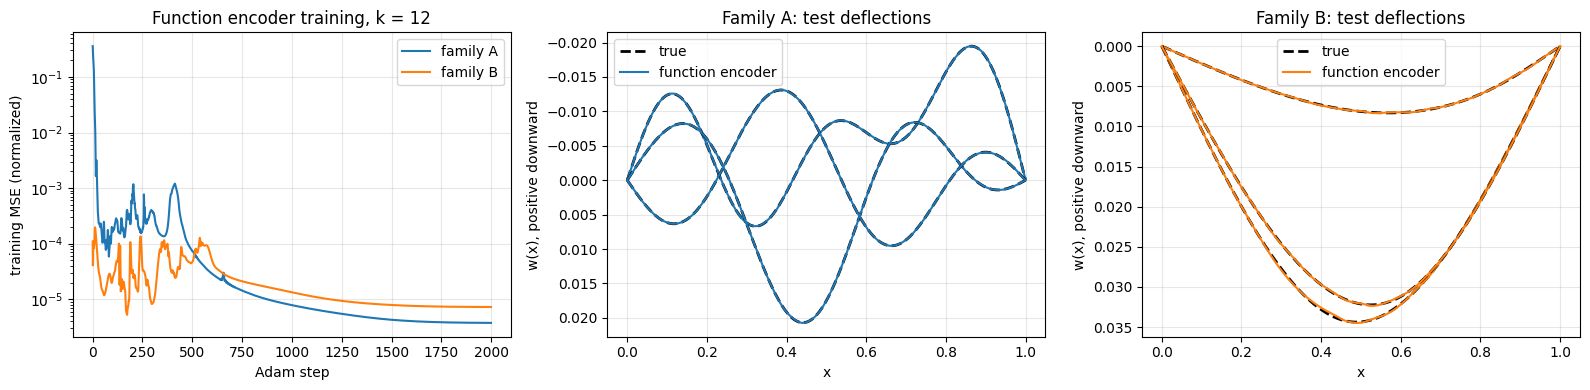

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].semilogy(histories["A"], color="tab:blue", label="family A")
axes[0].semilogy(histories["B"], color="tab:orange", label="family B")
axes[0].set_xlabel("Adam step")
axes[0].set_ylabel("training MSE (normalized)")
axes[0].set_title("Function encoder training, k = 12")
axes[0].legend()

for ax, name, F_test, scale, c in [(axes[1], "A", F_A_test, scale_A, "tab:blue"),
                                   (axes[2], "B", F_B_test, scale_B, "tab:orange")]:
    with torch.no_grad():
        Phi = models[name](x_t)
        recon = (Phi @ coefficients(Phi, F_test[:3])).T.numpy() * scale
    for i in range(3):
        ax.plot(x, F_test[i].numpy() * scale, "k--", lw=2, label="true" if i == 0 else None)
        ax.plot(x, recon[i], color=c, lw=1.5, label="function encoder" if i == 0 else None)
    ax.set_xlabel("x")
    ax.set_ylabel("w(x), positive downward")
    ax.invert_yaxis()
    ax.set_title(f"Family {name}: test deflections")
    ax.legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## The kernel of a function encoder

Stack the basis functions into the feature map $\boldsymbol{\phi}(x) = [\phi_1(x), \dots, \phi_k(x)]^T \in \mathbb{R}^k$.
Every function in the span is then an inner product, $\hat f(x) = \boldsymbol{\phi}(x)^T \alpha$, and the feature map defines the kernel

$$\kappa(x, x') = \boldsymbol{\phi}(x)^T \boldsymbol{\phi}(x') = \sum_{j=1}^{k} \phi_j(x)\, \phi_j(x').$$

Proposition 1 of Low et al. states that $\kappa$ is a valid reproducing kernel.
On the grid the kernel matrix is $K = \Phi \Phi^T \in \mathbb{R}^{m \times m}$ with $K_{il} = \kappa(x_i, x_l)$.
The matrix $K$ is symmetric because $(\Phi\Phi^T)^T = \Phi\Phi^T$.
It is positive semidefinite because $z^T K z = \|\Phi^T z\|^2 \ge 0$ for every $z \in \mathbb{R}^m$.
Its rank is at most $k$, since $K$ maps $\mathbb{R}^m$ into $\mathbb{R}^m$ through $\mathbb{R}^k$.

For comparison we use the Gaussian RBF kernel $\kappa_{\text{RBF}}(x, x') = \exp(-(x - x')^2 / (2\ell^2))$ with $\ell = 0.1$.
Its matrix on the same grid is also symmetric positive semidefinite.

In [7]:
with torch.no_grad():
    Phi_grid = {name: models[name](x_t).numpy() for name in ["A", "B"]}
K_learned = {name: Phi_grid[name] @ Phi_grid[name].T for name in ["A", "B"]}

ell = 0.1
K_rbf = np.exp(-(x[:, None] - x[None, :]) ** 2 / (2 * ell**2))

for label, K in [("learned A", K_learned["A"]), ("learned B", K_learned["B"]), ("RBF", K_rbf)]:
    eig = np.linalg.eigvalsh(K)
    print(f"{label:9s}: max|K - K^T| {np.abs(K - K.T).max():.1e}, smallest eigenvalue {eig[0]:.1e}, "
          f"largest {eig[-1]:.2e}, eigenvalues above 1e-10 x largest: {np.sum(eig > 1e-10 * eig[-1])}")

# Reproducing property on the grid: (1/m) sum_x' kappa(x, x') f(x') = f(x) for f in the span of an orthonormal basis
for name, F_test in [("A", F_A_test), ("B", F_B_test)]:
    Ft = F_test.numpy()
    Kf = Ft @ K_learned[name] / m
    rel = np.linalg.norm(Kf - Ft, axis=1) / np.linalg.norm(Ft, axis=1)
    print(f"family {name}: mean relative error of (1/m) K f against f over test deflections {rel.mean():.1e}")

for name in ["A", "B"]:
    with torch.no_grad():
        phi_pts = models[name](torch.tensor([0.0, 0.5, 1.0])).numpy()
    diag = (phi_pts**2).sum(axis=1)          # kappa(x, x) = |phi(x)|^2
    print(f"family {name}: kappa(x, x) at x = 0, 0.5, 1: {diag[0]:.1f}, {diag[1]:.1f}, {diag[2]:.1f}")

learned A: max|K - K^T| 0.0e+00, smallest eigenvalue -1.3e-13, largest 2.01e+02, eigenvalues above 1e-10 x largest: 12
learned B: max|K - K^T| 0.0e+00, smallest eigenvalue -1.2e-13, largest 2.02e+02, eigenvalues above 1e-10 x largest: 12
RBF      : max|K - K^T| 0.0e+00, smallest eigenvalue -1.1e-14, largest 4.80e+01, eigenvalues above 1e-10 x largest: 26
family A: mean relative error of (1/m) K f against f over test deflections 3.3e-03
family B: mean relative error of (1/m) K f against f over test deflections 4.0e-03
family A: kappa(x, x) at x = 0, 0.5, 1: 40.1, 7.0, 45.1
family B: kappa(x, x) at x = 0, 0.5, 1: 34.2, 13.5, 28.4


Both learned kernel matrices are exactly symmetric.
Their smallest eigenvalues, $-1.3 \times 10^{-13}$ and $-1.2 \times 10^{-13}$, are rounding errors around zero.
Each $200 \times 200$ learned matrix has 12 eigenvalues above $10^{-10}$ times the largest, one per basis function.
The RBF matrix has 26 eigenvalues above the same cutoff.

The learned kernel also reproduces the deflections.
For an orthonormal basis and a function $f$ in its span, $\frac{1}{m} \sum_{l} \kappa(x, x_l) f(x_l) = \sum_j \phi_j(x) \langle \phi_j, f \rangle = f(x)$, which on the grid reads $\frac{1}{m} K f = f$.
The relative error of $\frac{1}{m} K f$ over the test deflections is $3.3 \times 10^{-3}$ for family A and $4.0 \times 10^{-3}$ for family B.
The error comes from $G$ differing from $I$.
Up to this error, $\frac{1}{m} K$ is the orthogonal projection onto the span of the basis.
The last two lines print the diagonal $\kappa(x, x) = \|\boldsymbol{\phi}(x)\|^2$ at the supports and at midspan.

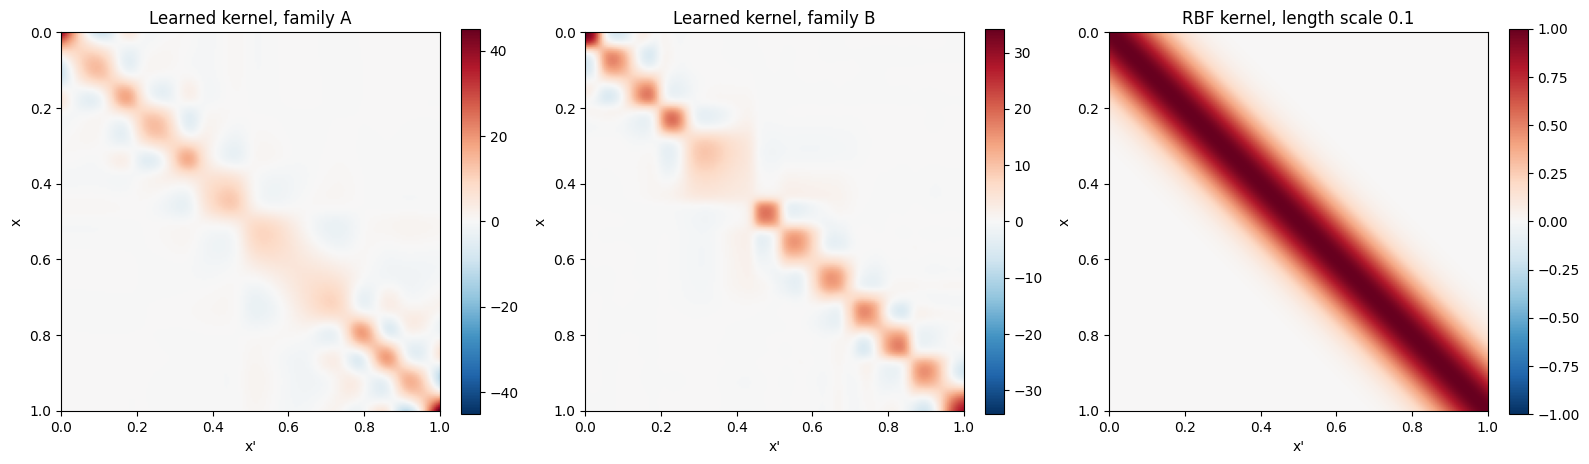

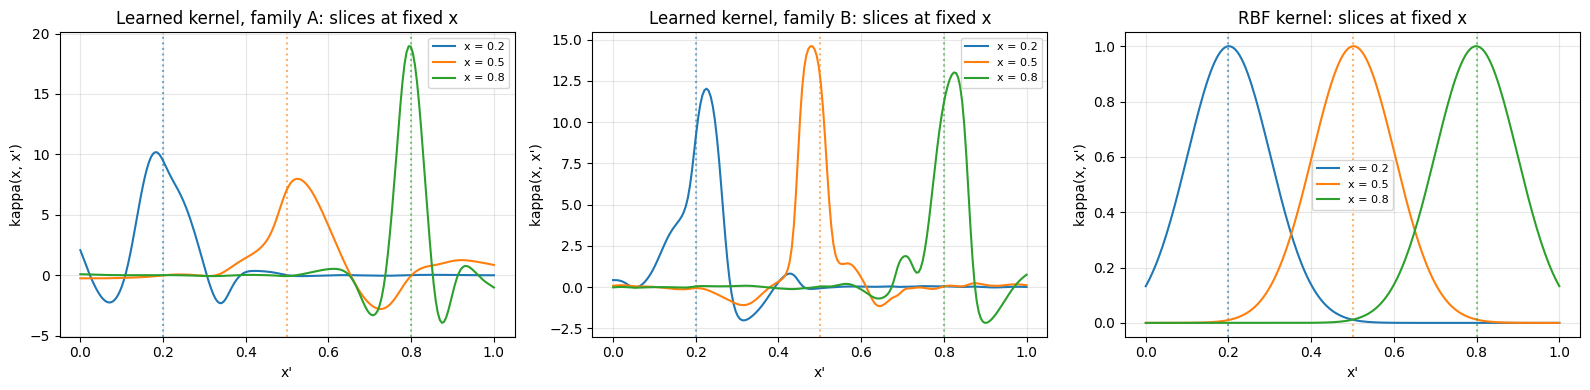

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, K, title in [(axes[0], K_learned["A"], "Learned kernel, family A"),
                     (axes[1], K_learned["B"], "Learned kernel, family B"),
                     (axes[2], K_rbf, f"RBF kernel, length scale {ell}")]:
    vmax = np.abs(K).max()
    im = ax.imshow(K, cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=[0, 1, 1, 0])
    ax.set_xlabel("x'")
    ax.set_ylabel("x")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

x0_list = [0.2, 0.5, 0.8]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, K, title in [(axes[0], K_learned["A"], "Learned kernel, family A"),
                     (axes[1], K_learned["B"], "Learned kernel, family B"),
                     (axes[2], K_rbf, "RBF kernel")]:
    for x0, c in zip(x0_list, ["tab:blue", "tab:orange", "tab:green"]):
        i0 = np.argmin(np.abs(x - x0))
        ax.plot(x, K[i0], color=c, label=f"x = {x0}")
        ax.axvline(x0, color=c, ls=":", alpha=0.6)
    ax.set_xlabel("x'")
    ax.set_ylabel("kappa(x, x')")
    ax.set_title(f"{title}: slices at fixed x")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The heatmaps show where each kernel puts its weight.
All three concentrate near the diagonal $x = x'$, so in each kernel nearby points are similar.
The RBF kernel is the same Gaussian of width $\ell$ at every $x$, and it does not depend on the data.
Its slices are translated copies of one bump.
The learned kernels depend on the family.
Their slices change height and width with $x$, they have side lobes of both signs, and family A and family B give different kernels on the same deck.
For an orthonormal basis, $\kappa$ depends only on the span, because an orthogonal change of basis $\boldsymbol{\phi} \to Q \boldsymbol{\phi}$ leaves $\boldsymbol{\phi}(x)^T \boldsymbol{\phi}(x')$ unchanged.
Training chooses the span, and the span decides the kernel.

The learned kernels are also largest near the corners $(0, 0)$ and $(1, 1)$ of the heatmaps.
The last printed lines give $\kappa(0, 0) = 40.1$ and $\kappa(1, 1) = 45.1$ against $\kappa(0.5, 0.5) = 7.0$ for family A, and 34.2 and 28.4 against 13.5 for family B.
Every deflection of both families vanishes at the supports, so the training data never calls for nonzero values there.
Some of the 12 basis directions carry almost no deflection variance, and the kernel weighs them as much as the directions the family uses.
Section 4 shows the effect on a noisy fit.

## Primal and dual solutions

Now a three-axle truck with axles at $0.30$, $0.45$, $0.65$ and axle loads $0.8$, $1.6$, $1.6$ crosses the deck.
The truck is not in the training set.
We observe its deflection at $m = 20$ random points with Gaussian noise of standard deviation $\sigma = 0.05$ on the normalized scale, and fit it with the family B basis.
The primal problem is ridge regression in coefficient space,

$$\alpha = (\Phi^T \Phi + \lambda I)^{-1} \Phi^T y, \qquad \hat f(x) = \boldsymbol{\phi}(x)^T \alpha,$$

where $\Phi \in \mathbb{R}^{m \times k}$ now holds the basis at the 20 observation points and $y \in \mathbb{R}^m$ holds the noisy observations.
The dual problem is kernel ridge regression with the learned kernel,

$$\beta = (K + \lambda I)^{-1} y, \qquad \hat f(x) = \sum_{l=1}^{m} \beta_l\, \kappa(x, x_l),$$

with $K_{il} = \kappa(x_i, x_l)$ and the same $\lambda = 10^{-2}$.
The two predictors are equal.
Multiplying out gives $\Phi^T (\Phi \Phi^T + \lambda I) = (\Phi^T \Phi + \lambda I) \Phi^T$, and inverting both factors gives $(\Phi^T \Phi + \lambda I)^{-1} \Phi^T = \Phi^T (\Phi \Phi^T + \lambda I)^{-1}$.
Hence $\alpha = \Phi^T \beta$ and $\boldsymbol{\phi}(x)^T \alpha = \boldsymbol{\phi}(x)^T \Phi^T \beta = \sum_l \beta_l \kappa(x, x_l)$.
Low et al. write the dual system as $(K + \lambda' m I)\beta = Y$ with the $\lambda'$ of their equation (3) (Section 3.1), so the correspondence $\lambda = m\lambda'$ makes our primal and dual systems the two forms of their problem.

In [9]:
# A three-axle truck that is not in the training set
truck_positions = np.array([0.30, 0.45, 0.65])
truck_loads = np.array([0.8, 1.6, 1.6])
m_obs, sigma, lam_fit = 20, 0.05, 1e-2

x_obs = np.sort(rng.uniform(0.0, L, m_obs))
y_obs = vehicle_deflection(x_obs, truck_positions, truck_loads) / scale_B + sigma * rng.standard_normal(m_obs)
x_fine = np.linspace(0.0, L, 500)
w_fine = vehicle_deflection(x_fine, truck_positions, truck_loads) / scale_B

with torch.no_grad():
    Phi_obs = models["B"](torch.tensor(x_obs)).numpy()      # (m_obs, k)
    Phi_fine = models["B"](torch.tensor(x_fine)).numpy()    # (500, k)

# Primal: k x k system
alpha = np.linalg.solve(Phi_obs.T @ Phi_obs + lam_fit * np.eye(k), Phi_obs.T @ y_obs)
f_primal = Phi_fine @ alpha

# Dual: m_obs x m_obs system with K_ij = kappa(x_i, x_j)
K_obs = Phi_obs @ Phi_obs.T
beta = np.linalg.solve(K_obs + lam_fit * np.eye(m_obs), y_obs)
f_dual = (Phi_fine @ Phi_obs.T) @ beta                    # sum_j beta_j kappa(x, x_j)

print(f"max |f_primal - f_dual| on 500 points: {np.abs(f_primal - f_dual).max():.1e}")
print(f"max |alpha - Phi^T beta|: {np.abs(alpha - Phi_obs.T @ beta).max():.1e}")
print(f"condition number of K + lambda I: {np.linalg.cond(K_obs + lam_fit * np.eye(m_obs)):.1e}")

max |f_primal - f_dual| on 500 points: 2.8e-13
max |alpha - Phi^T beta|: 3.4e-14
condition number of K + lambda I: 5.9e+03


The primal and dual predictions agree to $2.8 \times 10^{-13}$ on 500 points, and $\alpha$ agrees with $\Phi^T\beta$ to $3.4 \times 10^{-14}$.
The condition number of $K + \lambda I$ is $5.9 \times 10^{3}$, and differences of this size are the rounding error of a solve with this condition number in double precision.

One noisy draw can be lucky.
We repeat the fit for 100 draws of the 20 points and the noise and report the mean RMSE against the true deflection on the normalized scale.
For comparison we run kernel ridge regression with the RBF kernel at four length scales and the same $\lambda$.

In [10]:
trial_rng = np.random.default_rng(1)
trials = []
for _ in range(100):
    xo = np.sort(trial_rng.uniform(0.0, L, m_obs))
    yo = vehicle_deflection(xo, truck_positions, truck_loads) / scale_B + sigma * trial_rng.standard_normal(m_obs)
    trials.append((xo, yo))


def rbf(xa, xb, ell_r):
    return np.exp(-(xa[:, None] - xb[None, :]) ** 2 / (2 * ell_r**2))


def mean_rmse_learned(model):
    with torch.no_grad():
        Pf = model(torch.tensor(x_fine)).numpy()
    errors = []
    for xo, yo in trials:
        with torch.no_grad():
            Po = model(torch.tensor(xo)).numpy()
        a = np.linalg.solve(Po.T @ Po + lam_fit * np.eye(Po.shape[1]), Po.T @ yo)
        errors.append(np.sqrt(np.mean((Pf @ a - w_fine) ** 2)))
    return np.mean(errors)


def mean_rmse_rbf(ell_r):
    errors = []
    for xo, yo in trials:
        b = np.linalg.solve(rbf(xo, xo, ell_r) + lam_fit * np.eye(len(xo)), yo)
        errors.append(np.sqrt(np.mean((rbf(x_fine, xo, ell_r) @ b - w_fine) ** 2)))
    return np.mean(errors)


print(f"mean RMSE over {len(trials)} noisy draws, learned kernel k={k}: {mean_rmse_learned(models['B']):.3f}")
rbf_rmse = {ell_r: mean_rmse_rbf(ell_r) for ell_r in [0.05, 0.1, 0.2, 0.4]}
for ell_r, e in rbf_rmse.items():
    print(f"mean RMSE over {len(trials)} noisy draws, RBF kernel, length scale {ell_r}: {e:.3f}")
ell_best = min(rbf_rmse, key=rbf_rmse.get)
beta_rbf = np.linalg.solve(rbf(x_obs, x_obs, ell_best) + lam_fit * np.eye(m_obs), y_obs)
f_rbf = rbf(x_fine, x_obs, ell_best) @ beta_rbf

mean RMSE over 100 noisy draws, learned kernel k=12: 0.218
mean RMSE over 100 noisy draws, RBF kernel, length scale 0.05: 0.365
mean RMSE over 100 noisy draws, RBF kernel, length scale 0.1: 0.075
mean RMSE over 100 noisy draws, RBF kernel, length scale 0.2: 0.049
mean RMSE over 100 noisy draws, RBF kernel, length scale 0.4: 0.049


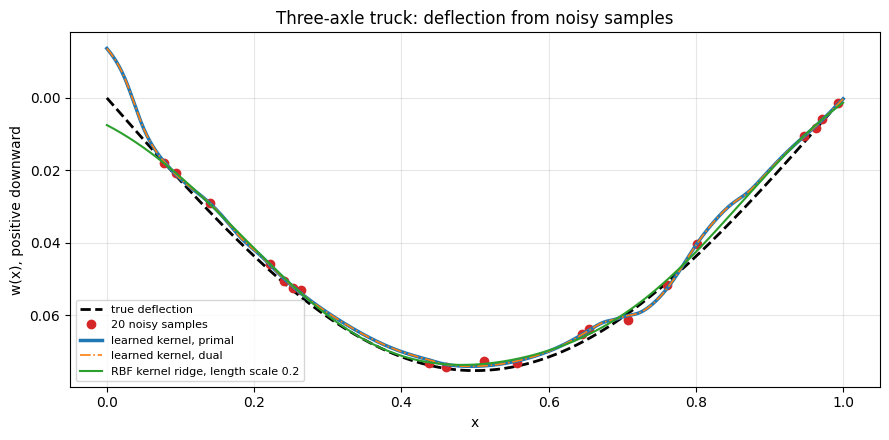

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_fine, w_fine * scale_B, "k--", lw=2, label="true deflection")
ax.plot(x_obs, y_obs * scale_B, "o", color="tab:red", label=f"{m_obs} noisy samples")
ax.plot(x_fine, f_primal * scale_B, color="tab:blue", lw=2.5, label="learned kernel, primal")
ax.plot(x_fine, f_dual * scale_B, color="tab:orange", lw=1.2, ls="-.", label="learned kernel, dual")
ax.plot(x_fine, f_rbf * scale_B, color="tab:green", lw=1.5,
        label=f"RBF kernel ridge, length scale {ell_best}")
ax.set_xlabel("x")
ax.set_ylabel("w(x), positive downward")
ax.invert_yaxis()
ax.set_title("Three-axle truck: deflection from noisy samples")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The figure shows one draw, and the primal and dual curves lie on top of each other.
Over the 100 draws, the learned kernel with 12 basis functions has mean RMSE 0.218.
The RBF kernel reaches 0.049 at length scales 0.2 and 0.4.
Kernel ridge regression with $\kappa$ is the primal problem with the penalty $\lambda \|\alpha\|^2$, which treats the 12 coefficients alike.
Twenty noisy samples then fit noise along directions in which the family has almost no variance.
At the left support, where no sample falls nearby, the fitted curve departs from the zero deflection.
Section 5 measures how many directions the family uses and returns to this fit with a smaller basis.

## What the two predictors are made of

Kernel ridge regression writes the prediction as a sum over the samples,

$$\hat f(x) = \sum_{l=1}^{m} \beta_l\, \kappa(x, x_l).$$

Each sample contributes one function $\kappa(\cdot, x_l)$ centered at that sample.
The predictor is built from $m$ pieces, and the pieces move with the data.
A function encoder writes the prediction as $\hat f(x) = \sum_{j=1}^{k} \alpha_j \phi_j(x)$.
The pieces are the $k$ basis functions learned from the family, the same for every new function, and the data only sets the $k$ weights.
The figure draws both constructions for the truck from 20 and from 80 noisy samples, with the RBF kernel at its best length scale.
Thin lines are the weighted pieces and the thick line is their sum.

RBF kernel ridge, m = 20: 20 pieces: RMSE 0.061, largest |piece| 7.44, largest |sum| 2.44
function encoder, m = 20: 12 pieces: RMSE 0.102, largest |piece| 2.34, largest |sum| 2.46
learned kernel, m = 20: rank of the 500 x 20 matrix of pieces kappa(., x_l) = 12
RBF kernel ridge, m = 80: 80 pieces: RMSE 0.017, largest |piece| 11.20, largest |sum| 2.49
function encoder, m = 80: 12 pieces: RMSE 0.023, largest |piece| 2.40, largest |sum| 2.49
learned kernel, m = 80: rank of the 500 x 80 matrix of pieces kappa(., x_l) = 12


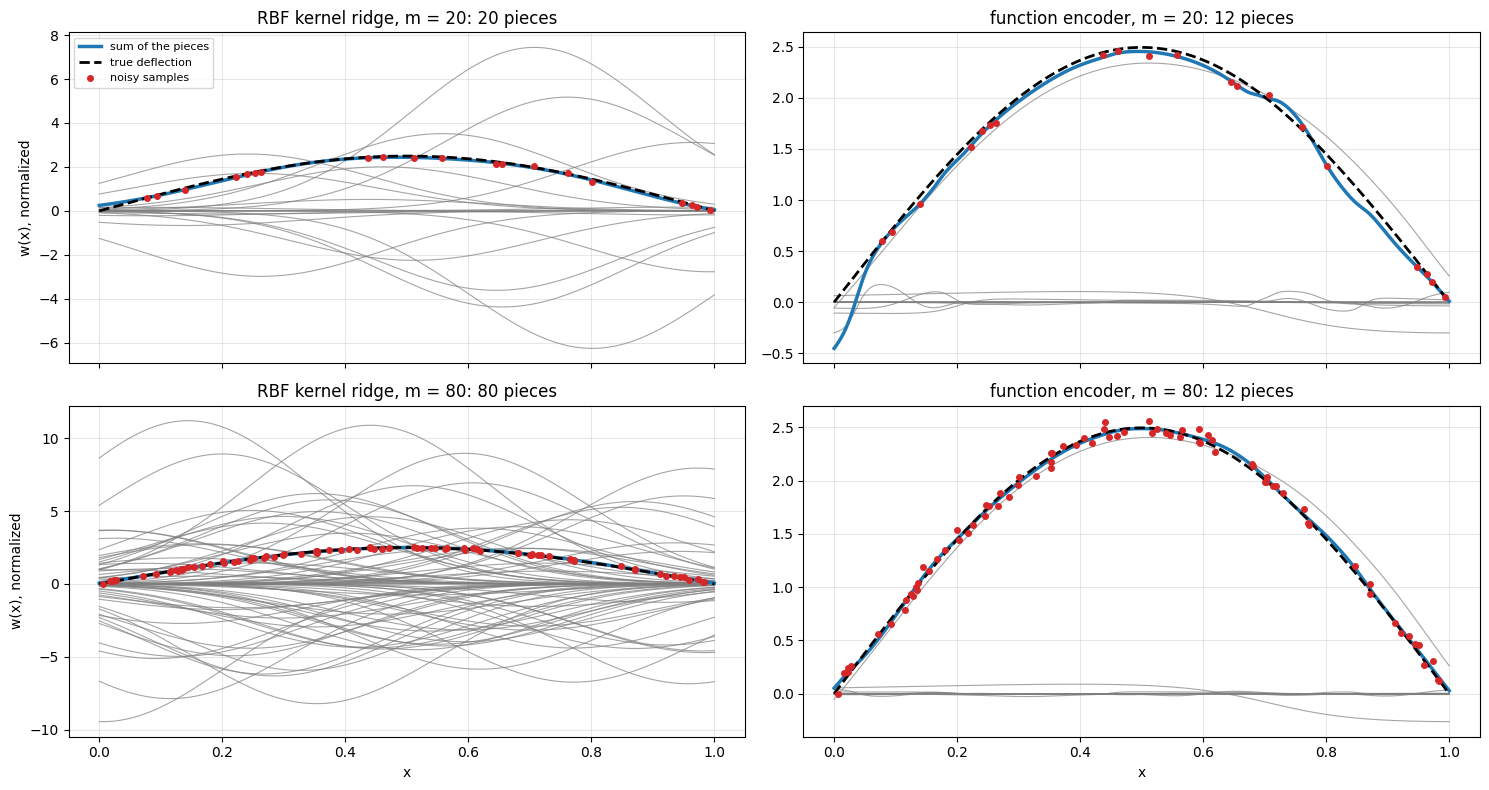

In [12]:
m_big = 80
x_obs_big = np.sort(rng.uniform(0.0, L, m_big))
y_obs_big = vehicle_deflection(x_obs_big, truck_positions, truck_loads) / scale_B + sigma * rng.standard_normal(m_big)

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for row, (xo, yo) in enumerate([(x_obs, y_obs), (x_obs_big, y_obs_big)]):
    mo = len(xo)
    # RBF kernel ridge: one piece per sample
    b = np.linalg.solve(rbf(xo, xo, ell_best) + lam_fit * np.eye(mo), yo)
    pieces_rbf = rbf(x_fine, xo, ell_best) * b[None, :]
    # function encoder: one piece per basis function
    with torch.no_grad():
        Po = models["B"](torch.tensor(xo)).numpy()
    a = np.linalg.solve(Po.T @ Po + lam_fit * np.eye(k), Po.T @ yo)
    pieces_fe = Phi_fine * a[None, :]
    for ax, pieces, title in [(axes[row, 0], pieces_rbf, f"RBF kernel ridge, m = {mo}: {mo} pieces"),
                              (axes[row, 1], pieces_fe, f"function encoder, m = {mo}: {k} pieces")]:
        ax.plot(x_fine, pieces, color="tab:gray", lw=0.8, alpha=0.7)
        ax.plot(x_fine, pieces.sum(axis=1), color="tab:blue", lw=2.5, label="sum of the pieces")
        ax.plot(x_fine, w_fine, "k--", lw=2, label="true deflection")
        ax.plot(xo, yo, "o", color="tab:red", ms=4, label="noisy samples")
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
        rmse = np.sqrt(np.mean((pieces.sum(axis=1) - w_fine) ** 2))
        print(f"{title}: RMSE {rmse:.3f}, largest |piece| {np.abs(pieces).max():.2f}, largest |sum| {np.abs(pieces.sum(axis=1)).max():.2f}")
    # the learned kernel's own pieces kappa(., x_l) are combinations of the k basis functions
    pieces_learned = Phi_fine @ Po.T
    print(f"learned kernel, m = {mo}: rank of the {len(x_fine)} x {mo} matrix of pieces kappa(., x_l) = {np.linalg.matrix_rank(pieces_learned)}")
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("w(x), normalized")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

With 20 samples the kernel predictor is a sum of 20 pieces, and with 80 samples a sum of 80.
The pieces are large and cancel.
Their largest value is 7.44 at $m = 20$ and 11.20 at $m = 80$, while the sum never exceeds 2.49, so most of each piece is undone by its neighbors.
The function encoder uses the same 12 pieces for both sample counts, the basis functions of family B, and the largest piece is 2.34 and 2.40, the size of the deflection itself.
The samples only change the 12 weights.
On this draw the RMSE is 0.061 and 0.017 for the kernel and 0.102 and 0.023 for the encoder, and Section 5 returns to this fit with fewer basis functions.

The learned kernel has pieces of its own, $\kappa(\cdot, x_l) = \boldsymbol{\phi}(\cdot)^T \boldsymbol{\phi}(x_l)$, one per sample.
Each is a combination of the 12 basis functions, so the matrix of 20 or 80 of them has rank 12.
A kernel with a finite feature map adds nothing beyond its basis, however many samples arrive, which is why the primal solve in the next section costs $O(k)$ per prediction and the dual $O(m)$ for the same answer.

The two forms have different costs.
The primal solve forms $\Phi^T \Phi$ in $O(m k^2)$ operations and solves a $k \times k$ system in $O(k^3)$, for $O(m k^2 + k^3)$ in total.
The dual solve forms $K$ in $O(m^2 k)$ and solves an $m \times m$ system in $O(m^3)$.
After the solve, the primal predictor evaluates $\boldsymbol{\phi}(x)^T \alpha$ with $k$ basis evaluations and a length-$k$ inner product, which is $O(k)$ per point.
The dual predictor $\sum_l \beta_l \kappa(x, x_l)$ needs one kernel evaluation per data point, which is $O(m)$ per point.
Slide 10 of the course deck states this as inference cost $O(k)$ for the basis against $O(m)$ for the data points.
With a learned feature map, the dual predictor converts to the primal one through $\alpha = \Phi^T\beta$.
The RBF kernel has no finite feature map, and its predictor stays at $O(m)$ per point.

We time both solves for $m$ = 50, 200, 800, and 3200 with $k = 12$.
The times are medians over repeated solves and change from run to run.

     m  primal (ms)    dual (ms)   max|primal - dual|
    50        0.010        0.024              8.1e-14
   200        0.012        0.173              2.0e-13


   800        0.022        3.197              5.9e-13


  3200        0.061       97.909              2.3e-12


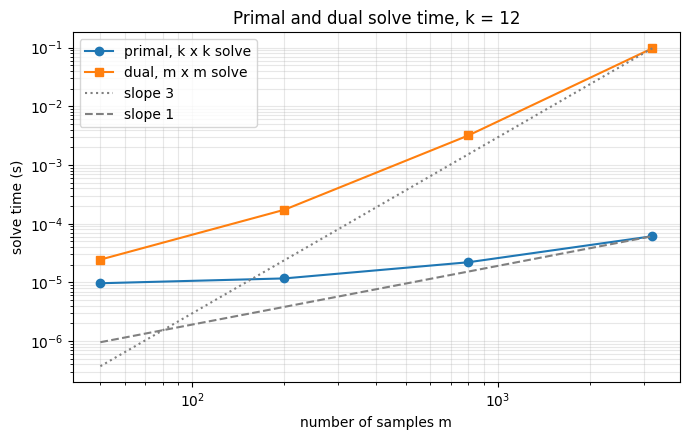

In [13]:
def median_time(fn, repeats):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return np.median(times)


m_list = [50, 200, 800, 3200]
t_primal, t_dual = [], []
print(f"{'m':>6s} {'primal (ms)':>12s} {'dual (ms)':>12s} {'max|primal - dual|':>20s}")
for m_s in m_list:
    xs = rng.uniform(0.0, L, m_s)
    ys = vehicle_deflection(xs, truck_positions, truck_loads) / scale_B + sigma * rng.standard_normal(m_s)
    with torch.no_grad():
        Ph = models["B"](torch.tensor(xs)).numpy()
    primal = lambda: np.linalg.solve(Ph.T @ Ph + lam_fit * np.eye(k), Ph.T @ ys)
    dual = lambda: np.linalg.solve(Ph @ Ph.T + lam_fit * np.eye(m_s), ys)
    t_primal.append(median_time(primal, 20))
    t_dual.append(median_time(dual, 3 if m_s >= 3200 else 10))
    diff = np.abs(Ph @ primal() - (Ph @ Ph.T) @ dual()).max()
    print(f"{m_s:6d} {1e3 * t_primal[-1]:12.3f} {1e3 * t_dual[-1]:12.3f} {diff:20.1e}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(m_list, t_primal, "o-", color="tab:blue", label="primal, k x k solve")
ax.loglog(m_list, t_dual, "s-", color="tab:orange", label="dual, m x m solve")
ref = np.array(m_list, dtype=float)
ax.loglog(ref, t_dual[-1] * (ref / ref[-1]) ** 3, color="gray", ls=":", label="slope 3")
ax.loglog(ref, t_primal[-1] * (ref / ref[-1]), color="gray", ls="--", label="slope 1")
ax.set_xlabel("number of samples m")
ax.set_ylabel("solve time (s)")
ax.set_title("Primal and dual solve time, k = 12")
ax.legend()
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

The primal time grows slowly over this range of $m$.
The dual time grows faster at every step, and between the two largest $m$ its growth comes close to the slope-3 reference line of the $O(m^3)$ solve.
The last column stays at the level of rounding error for every $m$, so the two solves give one predictor at two different costs.
The primal solve is faster at every $m$ in the table, and every $m$ in the table exceeds $k = 12$.
Low et al. state the same comparison, with the dual preferable when $m \ll k$ (Section 3.1).

## How many basis functions

The trained bases have $k = 12$ functions, and family A has dimension 5.
Low et al. read the number of basis functions a family needs from the coefficients of the training functions (Section 4.1).
With $\alpha^{(n)}$ the coefficient vector of training function $n$ and $\bar\alpha$ the mean over all $N$, the coefficient covariance is (their equation (7))

$$\Sigma = \frac{1}{N - 1} \sum_{n=1}^{N} (\alpha^{(n)} - \bar\alpha)(\alpha^{(n)} - \bar\alpha)^T \in \mathbb{R}^{k \times k}.$$

Let $\gamma_1 \ge \dots \ge \gamma_k$ be its eigenvalues (Low et al. write $\lambda_i$, which we keep for the ridge parameter).
The explained variance ratio of component $i$ is $\mathrm{EVR}_i = \gamma_i / \sum_{l=1}^{k} \gamma_l$, and the cumulative explained variance is $\mathrm{CEV}_r = \sum_{i=1}^{r} \mathrm{EVR}_i$.
The effective rank for a threshold $\tau$ is the smallest $r$ with $\mathrm{CEV}_r \ge \tau$ (their equation (8)).
This is principal component analysis in coefficient space.

Through an orthonormal basis, the coefficients are the coordinates of the deflections in an orthonormal frame.
The eigenvalues of $\Sigma$ are then the PCA eigenvalues of the deflections projected onto the span.
The code prints both sets for comparison.

In [14]:
def coefficient_spectrum(model, F):
    """Eigenvalues (descending) and eigenvectors of the coefficient covariance, Low et al. eq. (7)."""
    with torch.no_grad():
        Phi = model(x_t)
        C = coefficients(Phi, F).numpy().T                 # (N, k), row i is c^i
    Sigma = np.atleast_2d(np.cov(C, rowvar=False))       # 1/(N - 1) normalization
    eigvals, U = np.linalg.eigh(Sigma)
    order = np.argsort(eigvals)[::-1]
    return eigvals[order], U[:, order], Sigma


def effective_rank(eigvals, tau):
    """Smallest r with cumulative explained variance >= tau, Low et al. eq. (8)."""
    cev = np.cumsum(eigvals) / eigvals.sum()
    return int(np.argmax(cev >= tau) + 1)


def data_pca(F):
    """Covariance eigenvalues of the deflections themselves, inner product (1/m) sum over the grid."""
    Fc = F.numpy() - F.numpy().mean(axis=0)
    s = np.linalg.svd(Fc, compute_uv=False)
    return s**2 / ((F.shape[0] - 1) * m)


spectra = {}
for name, F in [("A", F_A), ("B", F_B)]:
    eigvals, U, Sigma = coefficient_spectrum(models[name], F)
    spectra[name] = (eigvals, U, Sigma)
    evr = eigvals / eigvals.sum()
    print(f"family {name}: eigenvalues of Sigma  {np.array2string(eigvals[:7], precision=2)}")
    print(f"family {name}: data PCA eigenvalues  {np.array2string(data_pca(F)[:7], precision=2)}")
    print(f"family {name}: EVR                   {np.array2string(evr[:7], precision=2)}")
    print(f"family {name}: CEV                   {np.array2string(np.cumsum(evr)[:7], precision=5)}")

family A: eigenvalues of Sigma  [2.43e-01 2.09e-01 2.00e-01 1.84e-01 1.65e-01 6.39e-17 1.91e-17]
family A: data PCA eigenvalues  [2.43e-01 2.09e-01 2.00e-01 1.84e-01 1.65e-01 1.37e-31 1.10e-31]
family A: EVR                   [2.43e-01 2.09e-01 2.00e-01 1.84e-01 1.65e-01 6.39e-17 1.91e-17]
family A: CEV                   [0.24279 0.45144 0.65142 0.83517 1.      1.      1.     ]
family B: eigenvalues of Sigma  [2.55e-01 2.12e-03 3.33e-05 2.80e-06 4.60e-07 9.24e-08 3.41e-08]
family B: data PCA eigenvalues  [2.55e-01 2.13e-03 3.48e-05 3.07e-06 4.99e-07 1.30e-07 3.75e-08]
family B: EVR                   [9.92e-01 8.26e-03 1.30e-04 1.09e-05 1.79e-06 3.60e-07 1.33e-07]
family B: CEV                   [0.9916  0.99986 0.99999 1.      1.      1.      1.     ]


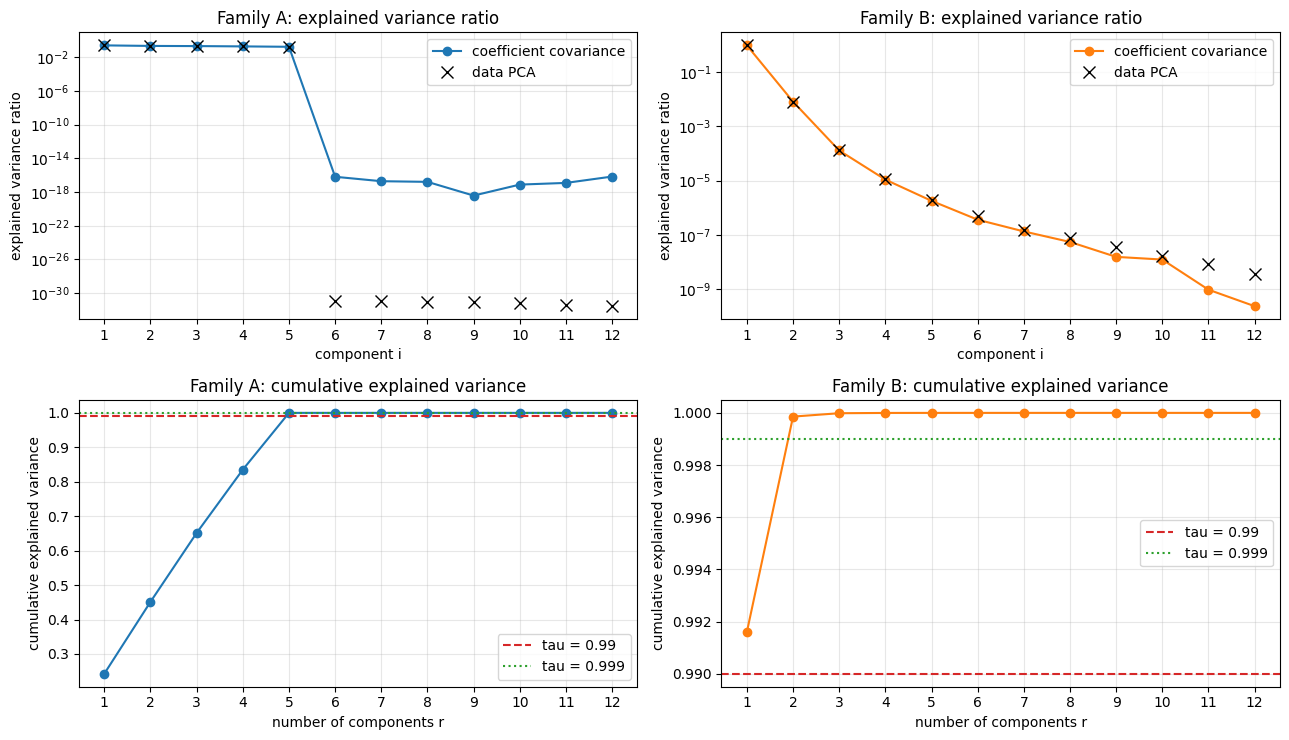

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
idx = np.arange(1, k + 1)
for col, (name, c) in enumerate([("A", "tab:blue"), ("B", "tab:orange")]):
    eigvals = spectra[name][0]
    evr = eigvals / eigvals.sum()
    pca = data_pca(F_A if name == "A" else F_B)[:k]
    ax = axes[0, col]
    # eigenvalues at rounding level can be slightly negative, so plot magnitudes
    ax.semilogy(idx, np.abs(evr), "o-", color=c, label="coefficient covariance")
    ax.semilogy(idx, np.abs(pca) / pca.sum(), "x", color="k", ms=8, label="data PCA")
    ax.set_xlabel("component i")
    ax.set_ylabel("explained variance ratio")
    ax.set_title(f"Family {name}: explained variance ratio")
    ax.legend()
    ax = axes[1, col]
    ax.plot(idx, np.cumsum(evr), "o-", color=c)
    ax.axhline(0.99, color="tab:red", ls="--", label="tau = 0.99")
    ax.axhline(0.999, color="tab:green", ls=":", label="tau = 0.999")
    ax.set_xlabel("number of components r")
    ax.set_ylabel("cumulative explained variance")
    ax.set_title(f"Family {name}: cumulative explained variance")
    ax.legend()
for ax in axes.ravel():
    ax.grid(True, alpha=0.3)
    ax.set_xticks(idx)
plt.tight_layout()
plt.show()

For family A the first five eigenvalues of $\Sigma$ agree with the data PCA eigenvalues to the printed digits, from $2.43 \times 10^{-1}$ down to $1.65 \times 10^{-1}$.
The sixth eigenvalue of $\Sigma$ is $6.39 \times 10^{-17}$, and the scree plot drops to rounding level after component 5.
The coefficient vectors lie in a 5-dimensional subspace of $\mathbb{R}^{12}$, because each deflection is a combination of five sines and the coefficients depend linearly on the deflection.
The cumulative explained variance is 0.83517 at four components and 1 at five, so $r = 5$ for every $\tau$ above 0.83517.

For family B the first component explains $\mathrm{EVR}_1 = 9.92 \times 10^{-1}$ of the variance.
The next components explain $8.26 \times 10^{-3}$, $1.30 \times 10^{-4}$, and $1.09 \times 10^{-5}$, and the spectrum decays without a cliff.
The sine series predicts this decay.
The amplitude of mode $j$ carries the factor $(j\pi)^{-4}$, its variance carries $(j\pi)^{-8}$, and the random axle positions spread variance over every mode.
The eigenvalues of $\Sigma$ track the data PCA eigenvalues, and in the scree plot they fall below them in the tail, where the 12 basis functions run out of directions.
With $\tau = 0.99$, family B keeps one component, since $\mathrm{CEV}_1 = 0.9916$.

In [16]:
# Same span, different basis: psi'_j = sum_{i <= j} psi_i, so Phi' = Phi T with T upper triangular ones.
# Least-squares coefficients transform as c' = T^{-1} c, so Sigma' = T^{-1} Sigma T^{-T}.
T_inv = np.linalg.inv(np.triu(np.ones((k, k))))
eigvals_A, _, Sigma_A = spectra["A"]
eig_mixed = np.sort(np.linalg.eigvalsh(T_inv @ Sigma_A @ T_inv.T))[::-1]
print("family A, EVR, near-orthonormal basis:", np.array2string((eigvals_A / eigvals_A.sum())[:5], precision=3))
print("family A, EVR, cumulative-sum basis:  ", np.array2string((eig_mixed / eig_mixed.sum())[:5], precision=3))

taus = [0.99, 0.999, 0.9999]
for name in ["A", "B"]:
    print(f"family {name}: r for tau = {taus}: {[effective_rank(spectra[name][0], t) for t in taus]}")

family A, EVR, near-orthonormal basis: [0.243 0.209 0.2   0.184 0.165]
family A, EVR, cumulative-sum basis:   [0.33  0.239 0.217 0.144 0.07 ]
family A: r for tau = [0.99, 0.999, 0.9999]: [5, 5, 5]
family B: r for tau = [0.99, 0.999, 0.9999]: [1, 2, 3]


The agreement with data PCA holds because the basis is close to orthonormal.
The cumulative-sum basis $\phi'_j = \sum_{i \le j} \phi_i$ spans the same space as the family A basis and gives the same predictions.
Its coefficients are $\alpha' = T^{-1} \alpha$, with $T$ the upper triangular matrix of ones, and its covariance is $T^{-1} \Sigma T^{-T}$.
The explained variance ratios change from 0.243, 0.209, 0.2, 0.184, 0.165 to 0.33, 0.239, 0.217, 0.144, 0.07, while the deflections stay the same.
The eigenvalues of $\Sigma$ describe the deflections only through an orthonormal basis, which is why the loss of Section 2 penalizes $\|G - I\|_F^2$.

The effective rank of family A is 5 at $\tau$ = 0.99, 0.999, and 0.9999.
The effective rank of family B is 1, 2, and 3 at the same thresholds.
The finite-dimensional family stops at its dimension.
The infinite-dimensional family adds one component each time $1 - \tau$ falls by a factor of 10 over this range.
For family B the threshold sets an accuracy, and no value of $\tau$ reveals a dimension.

Train-then-prune (Low et al., Section 4.2 and Algorithm 2) starts from an overparameterized basis trained jointly, here the $k = 12$ basis of Section 2.
It computes $r$ from $\Sigma$ and scores each basis function $\phi_p$ by

$$s_p = \sum_{i=1}^{r} \gamma_i\, U_{pi}^2,$$

where column $i$ of $U$ is the unit eigenvector of $\Sigma$ for $\gamma_i$.
The score $s_p$ is the diagonal entry $p$ of the rank-$r$ approximation $\sum_{i \le r} \gamma_i u_i u_i^T$ of $\Sigma$, the variance of coefficient $p$ along the top $r$ principal directions.
The method keeps the $r$ basis functions with the largest scores and fine-tunes the reduced basis on the same loss.
Jointly trained basis functions have no order, and $r$ of them need not span the top $r$ principal directions, which is why the fine-tuning step is part of the algorithm.
We fine-tune for 1000 Adam steps, half the original training, and run the method at $\tau = 0.99$ and $\tau = 0.999$.

In [17]:
import copy

finetune_steps, finetune_lr = 1000, 1e-2


def train_then_prune(model, F, tau):
    """Low et al. Algorithm 2 applied to an already trained basis. Returns the pruned basis before fine-tuning."""
    eigvals, U, _ = coefficient_spectrum(model, F)
    r = effective_rank(eigvals, tau)
    scores = (eigvals[:r] * U[:, :r] ** 2).sum(axis=1)     # s_p = sum_{i <= r} lambda_i U_pi^2
    keep = np.argsort(scores)[::-1][:r]
    pruned = SeparateMLPBasis([copy.deepcopy(model.nets[p]) for p in keep])
    return pruned, r, keep


results = []
pruned_models = {}
for name, F, F_test in [("A", F_A, F_A_test), ("B", F_B, F_B_test)]:
    results.append((name, "full basis", "-", k, reconstruction_mse(models[name], F_test)))
    for tau in [0.99, 0.999]:
        pruned, r, keep = train_then_prune(models[name], F, tau)
        mse_before = reconstruction_mse(pruned, F_test)
        same_r = [t for (n, t) in pruned_models if n == name and pruned_models[(n, t)].n_basis == r]
        if same_r:                      # same r as a smaller tau, reuse the fine-tuned basis
            pruned = pruned_models[(name, same_r[0])]
        else:
            torch.manual_seed(2)
            t0 = time.time()
            train(lambda: pruned(x_t), pruned.parameters(), F, finetune_steps, finetune_lr)
            print(f"family {name}, tau={tau}: r={r}, kept basis indices {sorted(keep.tolist())}, "
                  f"fine-tune time {time.time() - t0:.1f} s")
        pruned_models[(name, tau)] = pruned
        results.append((name, "pruned, before fine-tune", tau, r, mse_before))
        results.append((name, "pruned, after fine-tune", tau, r, reconstruction_mse(pruned, F_test)))

family A, tau=0.99: r=5, kept basis indices [2, 3, 4, 8, 11], fine-tune time 1.8 s


family B, tau=0.99: r=1, kept basis indices [9], fine-tune time 0.9 s


family B, tau=0.999: r=2, kept basis indices [0, 9], fine-tune time 1.1 s


Progressive training (Low et al., Section 4.1 and Algorithm 1) grows the basis one function at a time.
At step $b$ a new network $\phi_b$ joins the frozen $\phi_1, \dots, \phi_{b-1}$.
Adam trains only $\phi_b$ on the loss of Section 2, with coefficients from the ridge solve over all $b$ functions, so the new function fits what the frozen ones leave unexplained.
After each step we form $\Sigma_b$ from the $b$ coefficients of every training function.
The $b$ eigenvalues of $\Sigma_b$ always give $\mathrm{CEV}_b = 1$, so the stopping test asks whether the first $b - 1$ components already reach $\tau$.
The test $\mathrm{CEV}_{b-1} \ge \tau$ is the same as $\mathrm{EVR}_b \le 1 - \tau$ for the newest component, the form used in Appendix D.1 of Low et al. with $1 - \tau = 1\%$.
We stop at the first such $b$ and keep $r = b - 1$ functions.
Each step trains for 2000 Adam steps with the learning rate decaying from $3 \times 10^{-2}$ on a cosine schedule.
Only the new network is evaluated with gradients, and the frozen columns of $\Phi$ are computed once per step $b$.

In [18]:
def progressive_training(F, taus, steps=2000, lr=3e-2, max_basis=8):
    """Low et al. Algorithm 1. Basis function b is trained with phi_1..phi_{b-1} frozen.
    For each tau, r = b - 1 at the first b whose newest component explains at most 1 - tau of the variance."""
    nets, history, r_found = [], [], {}
    for b in range(1, max_basis + 1):
        with torch.no_grad():
            Phi_frozen = SeparateMLPBasis(nets)(x_t) if nets else torch.zeros(m, 0)
        torch.manual_seed(100 + b)
        new = SeparateMLPBasis([make_mlp()])
        train(lambda: torch.cat([Phi_frozen, new(x_t)], dim=-1), new.parameters(), F, steps, lr)
        nets.append(new.nets[0])
        eigvals, _, _ = coefficient_spectrum(SeparateMLPBasis(nets), F)
        evr_new = eigvals[-1] / eigvals.sum()
        mse_b = reconstruction_mse(SeparateMLPBasis(nets), F)
        history.append((b, evr_new, mse_b))
        print(f"  b={b}: EVR of newest component {evr_new:.2e}, train MSE {mse_b:.2e}")
        for tau in taus:
            if tau not in r_found and b > 1 and evr_new <= 1 - tau:
                r_found[tau] = b - 1
        if len(r_found) == len(taus):
            break
    return nets, r_found, history


prog = {}
for name, F, F_test in [("A", F_A, F_A_test), ("B", F_B, F_B_test)]:
    print(f"family {name}")
    t0 = time.time()
    nets, r_found, history = progressive_training(F, [0.99, 0.999])
    prog[name] = (nets, r_found, history)
    print(f"  r found {r_found}, time {time.time() - t0:.1f} s")
    for tau, r in r_found.items():
        results.append((name, "progressive", tau, r, reconstruction_mse(SeparateMLPBasis(nets[:r]), F_test)))

family A


  b=1: EVR of newest component 1.00e+00, train MSE 7.57e-01


  b=2: EVR of newest component 4.62e-01, train MSE 5.49e-01


  b=3: EVR of newest component 3.07e-01, train MSE 3.49e-01


  b=4: EVR of newest component 2.20e-01, train MSE 1.65e-01


  b=5: EVR of newest component 1.65e-01, train MSE 2.07e-05


  b=6: EVR of newest component -3.50e-17, train MSE 2.00e-05
  r found {0.99: 5, 0.999: 5}, time 11.1 s
family B


  b=1: EVR of newest component 1.00e+00, train MSE 2.18e-03


  b=2: EVR of newest component 8.27e-03, train MSE 5.34e-05


  b=3: EVR of newest component 2.07e-05, train MSE 4.63e-05
  r found {0.99: 1, 0.999: 2}, time 5.4 s


In [19]:
print(f"{'family':6s} {'method':26s} {'tau':>7s} {'r':>3s} {'test MSE':>10s}")
for name, method, tau, r, mse in results:
    print(f"{name:6s} {method:26s} {str(tau):>7s} {r:3d} {mse:10.2e}")

family method                         tau   r   test MSE
A      full basis                       -  12   3.60e-06
A      pruned, before fine-tune      0.99   5   1.20e-01
A      pruned, after fine-tune       0.99   5   3.12e-05
A      pruned, before fine-tune     0.999   5   1.20e-01
A      pruned, after fine-tune      0.999   5   3.12e-05
B      full basis                       -  12   7.89e-06
B      pruned, before fine-tune      0.99   1   8.97e-03
B      pruned, after fine-tune       0.99   1   2.38e-03
B      pruned, before fine-tune     0.999   2   1.28e-03
B      pruned, after fine-tune      0.999   2   5.17e-05
A      progressive                   0.99   5   2.13e-05
A      progressive                  0.999   5   2.13e-05
B      progressive                   0.99   1   2.39e-03
B      progressive                  0.999   2   5.43e-05


For family A both methods find $r = 5$ at both thresholds, the dimension of the family.
Before fine-tuning, the five pruned functions give test MSE $1.20 \times 10^{-1}$, because five of twelve jointly trained functions do not span the five sine modes.
Fine-tuning brings the test MSE to $3.12 \times 10^{-5}$, and progressive training reaches $2.13 \times 10^{-5}$.
The full basis of 12 functions reaches $3.60 \times 10^{-6}$.
Low et al. report that fine-tuned pruned models match the overparameterized ones on their polynomial benchmark (Section 6.1).
In our runs a gap remains after 1000 fine-tuning steps.

For family B both methods find $r = 1$ at $\tau = 0.99$ and $r = 2$ at $\tau = 0.999$.
One basis function gives test MSE $2.38 \times 10^{-3}$ after pruning and fine-tuning and $2.39 \times 10^{-3}$ from progressive training.
Two functions give $5.17 \times 10^{-5}$ and $5.43 \times 10^{-5}$, and the full basis gives $7.89 \times 10^{-6}$.
A smaller $1 - \tau$ keeps more functions and lowers the error.

The third progressive function of family B explains $2.07 \times 10^{-5}$ of the variance, less than the $1.30 \times 10^{-4}$ of the third component of the full basis.
It lowers the training MSE only from $5.34 \times 10^{-5}$ to $4.63 \times 10^{-5}$.
The stopping rule cannot tell a family with no variance left from a new function that trained poorly.
At $\tau = 0.9999$ progressive training would stop at $r = 2$ here, while the full basis gives $r = 3$.

In [20]:
print(f"mean RMSE over {len(trials)} noisy draws, family B bases:")
print(f"  full basis, k={k}: {mean_rmse_learned(models['B']):.3f}")
for tau in [0.99, 0.999]:
    r = prog["B"][1][tau]
    print(f"  pruned, tau={tau}, r={pruned_models[('B', tau)].n_basis}: {mean_rmse_learned(pruned_models[('B', tau)]):.3f}")
    print(f"  progressive, tau={tau}, r={r}: {mean_rmse_learned(SeparateMLPBasis(prog['B'][0][:r])):.3f}")
print(f"  RBF kernel, length scale {ell_best}: {rbf_rmse[ell_best]:.3f}")

mean RMSE over 100 noisy draws, family B bases:
  full basis, k=12: 0.218
  pruned, tau=0.99, r=1: 0.014
  progressive, tau=0.99, r=1: 0.014
  pruned, tau=0.999, r=2: 0.018
  progressive, tau=0.999, r=2: 0.018
  RBF kernel, length scale 0.2: 0.049


The noisy truck fit of Section 4 improves as the basis shrinks.
Over the same 100 draws, the mean RMSE is 0.218 with 12 functions, 0.014 with one function from either method, and 0.018 with two.
The best RBF kernel gives 0.049.
A compact basis leaves fewer directions along which 20 noisy samples can fit noise.
At this noise level one function fits the truck better than two.

relative projection residual of sin(j pi x), j = 1..5: [4.6e-03 4.6e-03 3.8e-03 5.1e-03 5.4e-03]


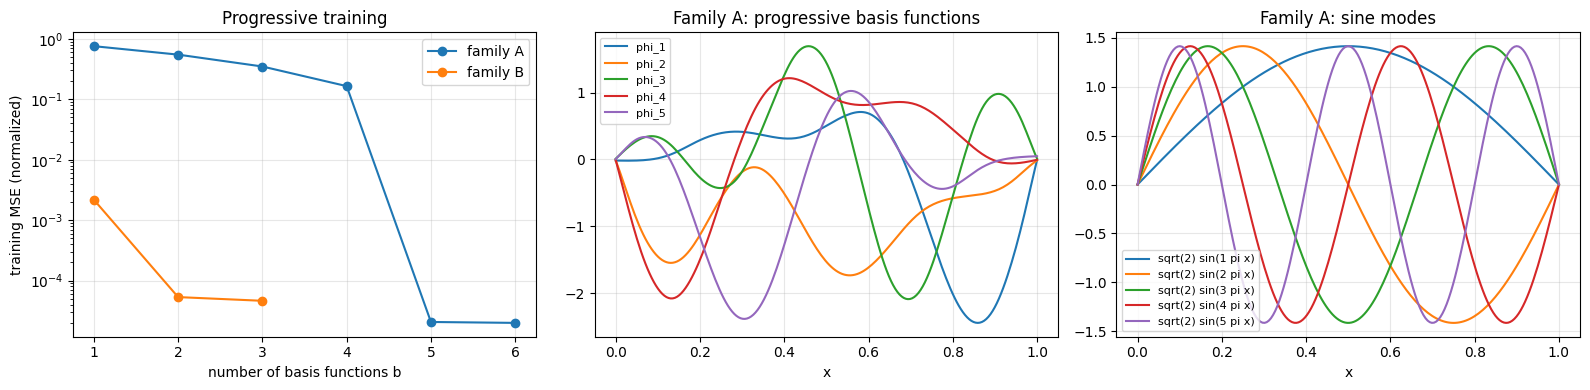

In [21]:
nets_A, r_A, hist_A = prog["A"]
r5 = r_A[0.99]
with torch.no_grad():
    Phi_prog = SeparateMLPBasis(nets_A[:r5])(x_t).numpy()
sine_modes = np.sqrt(2) * np.sin(np.pi * np.outer(x, modes))       # unit norm under (1/m) sum

# Relative residual of each sine mode after least-squares projection onto the progressive span
coef, *_ = np.linalg.lstsq(Phi_prog, sine_modes, rcond=None)
res = np.linalg.norm(sine_modes - Phi_prog @ coef, axis=0) / np.linalg.norm(sine_modes, axis=0)
print("relative projection residual of sin(j pi x), j = 1..5:", np.array2string(res, formatter={"float": lambda v: f"{v:.1e}"}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, c in [("A", "tab:blue"), ("B", "tab:orange")]:
    h = np.array(prog[name][2])
    axes[0].semilogy(h[:, 0], h[:, 2], "o-", color=c, label=f"family {name}")
axes[0].set_xlabel("number of basis functions b")
axes[0].set_ylabel("training MSE (normalized)")
axes[0].set_title("Progressive training")
axes[0].legend()
for j, c in enumerate(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"][:r5]):
    axes[1].plot(x, Phi_prog[:, j], color=c, label=f"phi_{j + 1}")
    axes[2].plot(x, sine_modes[:, j], color=c, label=f"sqrt(2) sin({j + 1} pi x)")
axes[1].set_title("Family A: progressive basis functions")
axes[2].set_title("Family A: sine modes")
for ax in axes[1:]:
    ax.set_xlabel("x")
    ax.legend(fontsize=8)
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The left panel shows the training MSE of progressive training.
For family A it falls in nearly equal steps up to $b = 4$ and drops to $2.07 \times 10^{-5}$ at $b = 5$, and the sixth function lowers it only to $2.00 \times 10^{-5}$.
For family B the first function leaves $2.18 \times 10^{-3}$, and the second brings it to $5.34 \times 10^{-5}$.

The five progressive basis functions of family A vanish at both supports, like the sines, but they are different functions.
Each mode $\sqrt{2} \sin(j\pi x)$ projects onto their span with a relative residual between $3.8 \times 10^{-3}$ and $5.4 \times 10^{-3}$, so the progressive basis spans the five modes to this accuracy.
Any invertible combination of the five sines spans the same space.
Progressive training orders the functions by explained variance, as PCA does, and the five components of family A explain nearly equal shares, from $2.43 \times 10^{-1}$ to $1.65 \times 10^{-1}$.
With nearly equal variances, the principal directions are mixtures of sines set by the sampled amplitudes, and the progressive functions are such mixtures.

## Closing remarks

A trained function encoder is a kernel method with a learned kernel.
On the bridge data the kernel $\kappa(x, x') = \boldsymbol{\phi}(x)^T \boldsymbol{\phi}(x')$ gave symmetric positive semidefinite matrices of rank 12.
The primal and dual solutions agreed to rounding error, and the dual solve time grew faster with $m$ than the primal one.
The coefficient covariance found the dimension 5 of family A with both algorithms of Low et al.
For family B it gave an effective rank that grows as $\tau$ approaches 1.
The size of the basis also decided the quality of a fit from few noisy samples.
The 12-function kernel fitted 20 samples of a truck worse than an RBF kernel, and the one- and two-function bases fitted them better.
Theorem 1 of Low et al. bounds the gap between the population risk and the empirical risk of the ridge predictor.
The bound grows with the number of basis functions and shrinks with $m$ and $\lambda$.
It is consistent with the ordering above, and Part 8 of `03-function-encoder.ipynb` checks it numerically.